In [16]:
import kairo
import pandas as pd

import warnings
warnings.filterwarnings("ignore")

from dotenv import load_dotenv
from pathlib import Path
import os

load_dotenv(Path("../..") / ".env")

True

In [17]:
log = kairo.read_log("../../data/control-flow.xes",
    case_id = "case:concept:name",
    activity = "concept:name",
    timestamp = "time:timestamp",
    event_id = "event:id",
    start_timestamp = "start_timestamp",
    resource = "org:resource",
    event_duration = "event:duration_min")
log.head()

,case:concept:name,time:timestamp,org:resource,event_id,concept:name,event_duration,case:region,start_timestamp,case:amount
0,case_000001,2020-01-01 00:26:42.410373+00:00,res_05,evt_00000001,a,26.706840,region_3,2020-01-01 00:00:00+00:00,647.69
1,case_000002,2020-01-01 00:55:21.249723+00:00,res_05,evt_00000002,a,54.064940,region_3,2020-01-01 00:01:17.353317+00:00,997.83
2,case_000002,2020-01-01 01:42:06.554846+00:00,res_04,evt_00000003,b,36.279715,region_3,2020-01-01 01:05:49.771917+00:00,997.83
3,case_000002,2020-01-01 02:37:36.979041+00:00,res_04,evt_00000004,c,44.312493,region_3,2020-01-01 01:53:18.229475+00:00,997.83
4,case_000002,2020-01-01 03:16:44.467898+00:00,res_06,evt_00000005,f,19.596884,region_3,2020-01-01 02:57:08.654875+00:00,997.83


In [18]:
stats = kairo.compute_log_stats(log)
stats

{'cases': 300299,
 'events': 1946540,
 'activities': 7,
 'resources': 7,
 'start': Timestamp('2020-01-01 00:23:35.993832+0000', tz='UTC'),
 'end': Timestamp('2021-01-01 19:23:21.884968+0000', tz='UTC'),
 'span_minutes': 528179.7648522666,
 'tpt_days_min': 0.0,
 'tpt_days_mean': 0.17814046984595158,
 'tpt_days_median': 0.0,
 'tpt_days_max': 3.0742563489583334,
 'length_min': 1,
 'length_mean': 6.482006267087137,
 'length_median': 1.0,
 'length_max': 94,
 'activity_counts': concept:name
 a    599657
 b    299358
 f    299358
 g    299358
 c    149907
 d    149451
 e    149451
 Name: count, dtype: int64,
 'resource_counts': org:resource
 res_03    618298
 res_05    453657
 res_04    334522
 res_01    216648
 res_06    173274
 res_07     94732
 res_02     55409
 Name: count, dtype: int64}

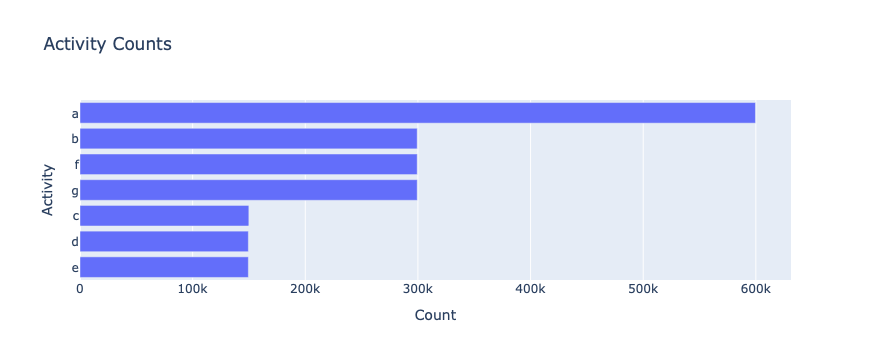

In [19]:
activity_plot = kairo.plot_activity_counts(stats)
activity_plot.show()

In [20]:
features = kairo.compute_features_intra(log, sliding_window_size=6)
features

,case:concept:name,time:timestamp,act_freqs:a,act_freqs:b,act_freqs:c,act_freqs:d,act_freqs:e,act_freqs:f,act_freqs:g,df_counts:a -> b,...,past_acts_5:e,past_acts_5:f,past_acts_5:g,past_acts_6:a,past_acts_6:b,past_acts_6:c,past_acts_6:d,past_acts_6:e,past_acts_6:f,past_acts_6:g
0,case_000001,2020-01-01 00:26:42.410373+00:00,1.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,case_000002,2020-01-01 00:55:21.249723+00:00,1.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,case_000002,2020-01-01 01:42:06.554846+00:00,0.500000,0.500000,0.000000,0.0,0.0,0.000000,0.000000,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,case_000002,2020-01-01 02:37:36.979041+00:00,0.333333,0.333333,0.333333,0.0,0.0,0.000000,0.000000,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,case_000002,2020-01-01 03:16:44.467898+00:00,0.250000,0.250000,0.250000,0.0,0.0,0.250000,0.000000,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1946535,case_300299,2020-12-31 01:22:22.655265+00:00,0.500000,0.500000,0.000000,0.0,0.0,0.000000,0.000000,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1946536,case_300299,2020-12-31 02:04:11.905257+00:00,0.333333,0.333333,0.333333,0.0,0.0,0.000000,0.000000,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1946537,case_300299,2020-12-31 02:20:44.237900+00:00,0.250000,0.250000,0.250000,0.0,0.0,0.250000,0.000000,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1946538,case_300299,2020-12-31 03:18:28.007451+00:00,0.200000,0.200000,0.200000,0.0,0.0,0.200000,0.200000,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [21]:
std_features = kairo.standardize(features, method="minmax")
std_features

,case:concept:name,time:timestamp,act_freqs:a,act_freqs:b,act_freqs:c,act_freqs:d,act_freqs:e,act_freqs:f,act_freqs:g,df_counts:a -> b,...,past_acts_5:e,past_acts_5:f,past_acts_5:g,past_acts_6:a,past_acts_6:b,past_acts_6:c,past_acts_6:d,past_acts_6:e,past_acts_6:f,past_acts_6:g
0,case_000001,2020-01-01 00:26:42.410373+00:00,1.00,0.000000,0.00,0.0,0.0,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,case_000002,2020-01-01 00:55:21.249723+00:00,1.00,0.000000,0.00,0.0,0.0,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,case_000002,2020-01-01 01:42:06.554846+00:00,0.40,1.000000,0.00,0.0,0.0,0.000000,0.000000,0.058824,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,case_000002,2020-01-01 02:37:36.979041+00:00,0.20,0.666667,1.00,0.0,0.0,0.000000,0.000000,0.058824,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,case_000002,2020-01-01 03:16:44.467898+00:00,0.10,0.500000,0.75,0.0,0.0,1.000000,0.000000,0.058824,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1946535,case_300299,2020-12-31 01:22:22.655265+00:00,0.40,1.000000,0.00,0.0,0.0,0.000000,0.000000,0.058824,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1946536,case_300299,2020-12-31 02:04:11.905257+00:00,0.20,0.666667,1.00,0.0,0.0,0.000000,0.000000,0.058824,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1946537,case_300299,2020-12-31 02:20:44.237900+00:00,0.10,0.500000,0.75,0.0,0.0,1.000000,0.000000,0.058824,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1946538,case_300299,2020-12-31 03:18:28.007451+00:00,0.04,0.400000,0.60,0.0,0.0,0.800000,1.000000,0.058824,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


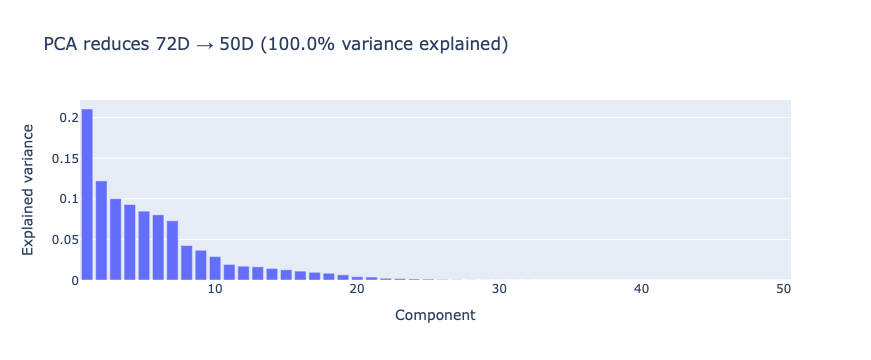

In [22]:
pca = kairo.compute_pca(std_features, num_components=50)
pca_plot = kairo.plot_pca_variances(pca)
pca_plot.show()
#pca

In [ ]:
reconstruction_errors = kairo.compute_pca_reconstruction_errors(std_features, pca)
reconstruction_plot = kairo.plot_pca_reconstruction_errors(reconstruction_errors)
reconstruction_plot.show()

In [23]:
compressed_features = kairo.apply_pca(std_features, pca, cut_component=18)
compressed_features

,case:concept:name,time:timestamp,pc_1,pc_2,pc_3,pc_4,pc_5,pc_6,pc_7,pc_8,pc_9,pc_10,pc_11,pc_12,pc_13,pc_14,pc_15,pc_16,pc_17,pc_18
0,case_000001,2020-01-01 00:26:42.410373+00:00,-1.802403,0.599726,-0.045007,-0.589702,0.041871,-0.197264,-0.197352,-0.329947,-0.653667,0.125023,0.133025,-0.022855,0.089967,-0.004696,0.057283,0.072111,0.373914,-0.056281
1,case_000002,2020-01-01 00:55:21.249723+00:00,-1.907466,0.523630,-0.048106,-0.560058,0.001203,-0.169869,-0.143199,-0.264468,-0.476354,0.111728,0.035578,-0.004108,0.000431,0.064230,-0.048314,-0.086108,-0.493145,0.115483
2,case_000002,2020-01-01 01:42:06.554846+00:00,-1.551906,-0.223184,-0.103086,0.159875,-0.376851,0.761655,0.668426,0.347662,0.592671,-0.196612,-0.292796,-0.401406,-0.393100,-0.351735,0.041181,0.161891,-0.033220,0.141323
3,case_000002,2020-01-01 02:37:36.979041+00:00,-1.193581,-0.488519,-0.782308,1.083045,0.130020,-0.542968,-0.308988,0.136071,0.771423,-0.095242,0.826427,0.332325,0.126438,-0.429552,-0.258614,-0.453746,-0.131446,-0.129282
4,case_000002,2020-01-01 03:16:44.467898+00:00,-0.341751,-0.859314,-0.308822,0.052605,1.698844,0.159740,0.049755,0.510359,0.380648,0.879280,-0.130783,0.548746,-0.137309,0.247378,0.521753,0.214509,-0.280137,-0.065003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1946535,case_300299,2020-12-31 01:22:22.655265+00:00,-1.527829,-0.205746,-0.102376,0.153082,-0.367531,0.755377,0.656015,0.332656,0.552037,-0.193565,-0.270465,-0.405702,-0.372582,-0.367530,0.065381,0.198150,0.165482,0.101960
1946536,case_300299,2020-12-31 02:04:11.905257+00:00,-1.157465,-0.462361,-0.781243,1.072855,0.144000,-0.552385,-0.327603,0.113562,0.710472,-0.090672,0.859924,0.325881,0.157216,-0.453245,-0.222315,-0.399358,0.166605,-0.188325
1946537,case_300299,2020-12-31 02:20:44.237900+00:00,-0.293597,-0.824437,-0.307402,0.039018,1.717483,0.147184,0.024935,0.480348,0.299379,0.885373,-0.086119,0.540154,-0.096272,0.215787,0.570152,0.287026,0.117266,-0.143728
1946538,case_300299,2020-12-31 03:18:28.007451+00:00,0.766862,-0.201597,-1.836023,-0.454008,0.168641,0.404220,-0.179086,-0.907014,0.326658,-0.189026,-0.387020,0.248080,-0.198150,0.337285,-0.100628,-0.348989,0.416537,0.260155


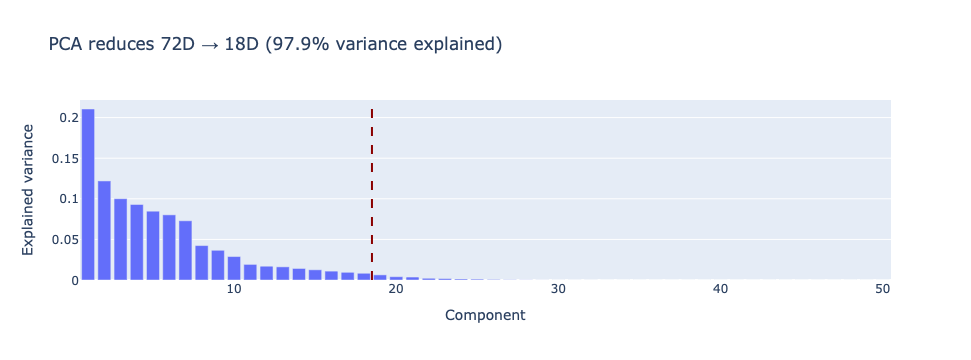

In [24]:
pca_plot_cut = kairo.plot_pca_variances(pca, cut_component=18)
pca_plot_cut.show()

In [ ]:
reconstruction_plot_cut = kairo.plot_pca_reconstruction_errors(reconstruction_errors, cut_component=18)
reconstruction_plot_cut.show()

In [ ]:
som = kairo.compute_som(compressed_features, size=(10,10))
clusters = kairo.get_som_states(compressed_features, som)
clusters

In [ ]:
clustering_scores = [
    {"type": "Quantization error", "value": kairo.compute_som_quantization_error(compressed_features, clusters, som)},
    {"type": "Occupancy entropy", "value": kairo.compute_som_occupancy_entropy(clusters, size=som.get_weights().shape[:2])},
    {"type": "Silhouette", "value": kairo.compute_silhouette(compressed_features, clusters)},
    {"type": "Calinski-Harabasz", "value": kairo.compute_calinski_harabasz(compressed_features, clusters)},
]
clustering_scores

In [26]:
features_and_clusters = pd.concat([compressed_features, clusters], axis=1)
features_and_clusters

,case:concept:name,time:timestamp,pc_1,pc_2,pc_3,pc_4,pc_5,pc_6,pc_7,pc_8,...,pc_11,pc_12,pc_13,pc_14,pc_15,pc_16,pc_17,pc_18,i,j
0,case_000001,2020-01-01 00:26:42.410373+00:00,-1.802403,0.599726,-0.045007,-0.589702,0.041871,-0.197264,-0.197352,-0.329947,...,0.133025,-0.022855,0.089967,-0.004696,0.057283,0.072111,0.373914,-0.056281,4,9
1,case_000002,2020-01-01 00:55:21.249723+00:00,-1.907466,0.523630,-0.048106,-0.560058,0.001203,-0.169869,-0.143199,-0.264468,...,0.035578,-0.004108,0.000431,0.064230,-0.048314,-0.086108,-0.493145,0.115483,6,9
2,case_000002,2020-01-01 01:42:06.554846+00:00,-1.551906,-0.223184,-0.103086,0.159875,-0.376851,0.761655,0.668426,0.347662,...,-0.292796,-0.401406,-0.393100,-0.351735,0.041181,0.161891,-0.033220,0.141323,8,9
3,case_000002,2020-01-01 02:37:36.979041+00:00,-1.193581,-0.488519,-0.782308,1.083045,0.130020,-0.542968,-0.308988,0.136071,...,0.826427,0.332325,0.126438,-0.429552,-0.258614,-0.453746,-0.131446,-0.129282,9,7
4,case_000002,2020-01-01 03:16:44.467898+00:00,-0.341751,-0.859314,-0.308822,0.052605,1.698844,0.159740,0.049755,0.510359,...,-0.130783,0.548746,-0.137309,0.247378,0.521753,0.214509,-0.280137,-0.065003,2,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1946535,case_300299,2020-12-31 01:22:22.655265+00:00,-1.527829,-0.205746,-0.102376,0.153082,-0.367531,0.755377,0.656015,0.332656,...,-0.270465,-0.405702,-0.372582,-0.367530,0.065381,0.198150,0.165482,0.101960,9,9
1946536,case_300299,2020-12-31 02:04:11.905257+00:00,-1.157465,-0.462361,-0.781243,1.072855,0.144000,-0.552385,-0.327603,0.113562,...,0.859924,0.325881,0.157216,-0.453245,-0.222315,-0.399358,0.166605,-0.188325,9,7
1946537,case_300299,2020-12-31 02:20:44.237900+00:00,-0.293597,-0.824437,-0.307402,0.039018,1.717483,0.147184,0.024935,0.480348,...,-0.086119,0.540154,-0.096272,0.215787,0.570152,0.287026,0.117266,-0.143728,3,7
1946538,case_300299,2020-12-31 03:18:28.007451+00:00,0.766862,-0.201597,-1.836023,-0.454008,0.168641,0.404220,-0.179086,-0.907014,...,-0.387020,0.248080,-0.198150,0.337285,-0.100628,-0.348989,0.416537,0.260155,0,4


In [27]:
state_distances = kairo.get_som_state_distances(som)
state_distances

,"(0, 0)","(0, 1)","(0, 2)","(0, 3)","(0, 4)","(0, 5)","(0, 6)","(0, 7)","(0, 8)","(0, 9)",...,"(9, 0)","(9, 1)","(9, 2)","(9, 3)","(9, 4)","(9, 5)","(9, 6)","(9, 7)","(9, 8)","(9, 9)"
"(0, 0)",0.000000,1.038714,1.780752,4.250084,4.019573,3.998265,3.311419,3.749612,3.881303,3.432598,...,3.307554,3.259296,2.796246,3.692018,3.359949,4.254235,4.020866,4.184629,3.800386,3.866949
"(0, 1)",1.038714,0.000000,1.320922,4.001793,3.789714,3.785979,3.286480,3.885289,3.745841,3.233094,...,3.071013,3.048750,2.737088,3.840370,3.295304,4.001476,3.819429,4.012253,3.785514,4.016149
"(0, 2)",1.780752,1.320922,0.000000,2.695734,2.589127,2.622569,2.464117,3.544449,3.345721,2.879075,...,2.633630,2.656912,2.275059,3.508615,2.758385,3.449801,3.246930,3.466172,3.216195,3.498889
"(0, 3)",4.250084,4.001793,2.695734,0.000000,1.297275,1.353890,2.614005,4.240165,4.022494,3.822071,...,3.566621,3.578078,3.312087,4.264116,3.408737,3.737717,3.547814,3.730384,3.529145,3.815791
"(0, 4)",4.019573,3.789714,2.589127,1.297275,0.000000,0.449297,2.246424,4.008621,3.807982,3.597230,...,3.311534,3.336460,3.019910,4.009152,3.098199,3.470816,3.275233,3.474356,3.259270,3.569521
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"(9, 5)",4.254235,4.001476,3.449801,3.737717,3.470816,3.473322,3.200224,3.983276,3.760234,3.701715,...,3.590861,3.580864,3.308441,4.253839,2.177206,0.000000,1.919433,2.618500,2.918138,3.702528
"(9, 6)",4.020866,3.819429,3.246930,3.547814,3.275233,3.249115,3.042831,3.908086,3.762530,3.589262,...,3.389152,3.342036,3.008640,3.981811,2.316500,1.919433,0.000000,0.701022,1.498819,2.744555
"(9, 7)",4.184629,4.012253,3.466172,3.730384,3.474356,3.439916,3.293966,4.135802,4.025247,3.821502,...,3.576723,3.519581,3.206602,4.135673,2.746669,2.618500,0.701022,0.000000,1.341673,2.670215
"(9, 8)",3.800386,3.785514,3.216195,3.529145,3.259270,3.220062,2.711443,3.459810,3.512075,3.283799,...,3.355478,3.291355,2.846447,3.744138,2.602932,2.918138,1.498819,1.341673,0.000000,1.328547


In [28]:
state_freqs = kairo.get_som_state_frequencies(features_and_clusters)
state_freqs

state
(0, 0)     45698
(0, 1)     18639
(0, 3)     25142
(0, 4)     37729
(0, 5)     37293
(0, 7)     49724
(0, 8)     24736
(1, 0)     54096
(1, 2)     31018
(1, 9)     24864
(2, 3)     49743
(2, 5)     37584
(2, 7)     37293
(2, 9)     50035
(3, 0)     74977
(3, 2)     49657
(3, 4)     18796
(3, 5)     18597
(3, 7)     37729
(4, 0)     11386
(4, 1)     13431
(4, 3)     24817
(4, 9)    150300
(5, 0)     49657
(5, 2)     25142
(5, 4)     12398
(5, 5)     37245
(5, 7)     37393
(5, 8)     37584
(6, 1)     30790
(6, 3)     10666
(6, 4)     14151
(6, 9)    149999
(7, 0)     49743
(7, 2)     18953
(7, 4)     12366
(7, 5)     24893
(7, 7)     37584
(7, 8)     37393
(8, 1)     25023
(8, 3)     49657
(8, 5)      8593
(8, 6)      3905
(8, 9)     74686
(9, 0)     37729
(9, 1)     37412
(9, 3)     24817
(9, 5)     25142
(9, 7)     75022
(9, 9)     75313
Name: events, dtype: int64

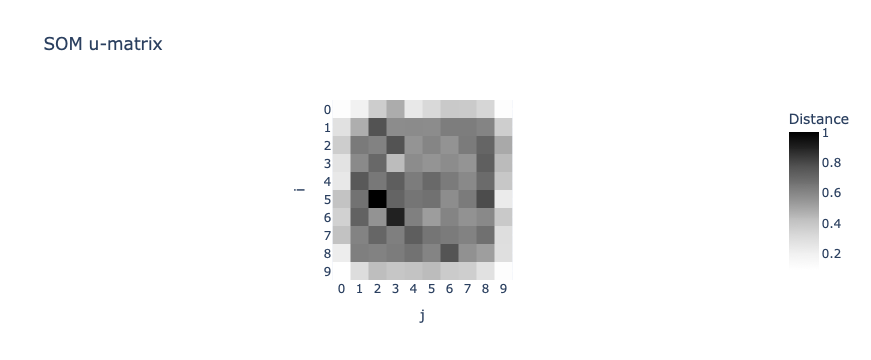

In [29]:
u_matrix_plot = kairo.plot_som_u_matrix(som)
u_matrix_plot.show()

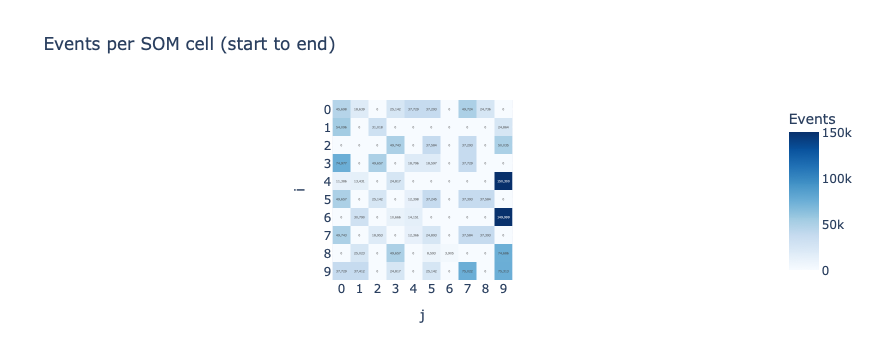

In [30]:
heatmap_plot = kairo.plot_som_heatmap(features_and_clusters, size=(10,10), 
                                 #start_date="2010-04-29", 
                                 #end_date="2018-05-29"
                                 )
heatmap_plot.show()

In [ ]:
state_colors = kairo.get_som_state_colors(som)
#state_colors

In [ ]:
state_colors_plot = kairo.plot_som_state_colors(features_and_clusters, state_colors)
state_colors_plot.show()

In [33]:
case_trajectory = kairo.get_som_case_trajectory(features_and_clusters, case_id="case_000001")
case_trajectory

,state,start,end,duration,events
0,"(4, 9)",2020-01-01 00:26:42.410373+00:00,2020-01-01 00:26:42.410373+00:00,0 days,1


In [ ]:
case_trajectory_plot = kairo.plot_som_case_trajectory(case_trajectory, state_colors, case_id="case_000001")
case_trajectory_plot

In [ ]:
case_trajectories = kairo.get_som_case_trajectories(features_and_clusters, max_cases=20)
case_trajectories

In [ ]:
case_trajectories_plot = kairo.plot_som_case_trajectories(case_trajectories, state_colors)
case_trajectories_plot

In [ ]:
freq_distributions = kairo.compute_state_distributions(features_and_clusters, signal_window="30D")
freq_distributions

In [ ]:
distributions_plot = kairo.plot_state_distributions(freq_distributions, state_colors)
distributions_plot.show()

In [ ]:
drift_signal = kairo.compute_drift_signal(freq_distributions)
drift_signal

In [ ]:
drift_signal_plot = kairo.plot_drift_signal(drift_signal)
drift_signal_plot.show()

In [41]:
abs_log_stats = kairo.abstract_log_stats(stats)
abs_log_stats

'Event log: 1,946,540 events of 300,299 cases, 7 activities and 7 resources, from 2020-01-01 00:23:35.993832+00:00 to 2021-01-01 19:23:21.884968+00:00.\nThroughput time per case in days: min 0.00, mean 0.18, median 0.00, max 3.07.\nEvents per case: min 1, mean 6.5, median 1.0, max 94.\nEvents per activity: a (599,657), b (299,358), f (299,358), g (299,358), c (149,907), d (149,451), e (149,451)\nMost active resources: res_03 (618,298), res_05 (453,657), res_04 (334,522), res_01 (216,648), res_06 (173,274), res_07 (94,732), res_02 (55,409)'

In [42]:
abs_features = kairo.abstract_features(features)
abs_features

'Intra-case feature matrix: 1,946,540 rows, one per event, each describing its case up to and including that event, with 72 feature columns.\nThe events belong to 300,299 cases.\nThey happened from 2020-01-01 00:23:35.993832+00:00 to 2021-01-01 19:23:21.884968+00:00.\nFeature groups:\n- act_freqs (share of every activity among the events of the case so far): 7 columns, mean value 0.143, non-zero in 65.5% of the cells, highest column means act_freqs:a = 0.374, act_freqs:b = 0.203, act_freqs:f = 0.112\n- df_counts (how often every directly-follows pair happened in the case so far): 8 columns, mean value 0.926, non-zero in 53.8% of the cells, highest column means df_counts:a -> b = 1.690, df_counts:f -> g = 1.151, df_counts:g -> a = 0.998\n- act_set (1 for every activity the case has already executed): 7 columns, mean value 0.655, non-zero in 65.5% of the cells, highest column means act_set:a = 1.000, act_set:b = 0.846, act_set:f = 0.653\n- case_progress (position of the event in its case

In [43]:
abs_pca = kairo.abstract_pca(pca, cut_component=13)
abs_pca

'PCA fitted 50 components on 72 feature columns. The cut keeps the first 13, which explain 92.4% of the variance.\nExplained variance per component: pc_1 21.1%, pc_2 12.2%, pc_3 10.0%, pc_4 9.3%, pc_5 8.5%, pc_6 8.0%, pc_7 7.3%, pc_8 4.2%, pc_9 3.7%, pc_10 2.9%, pc_11 1.9%, pc_12 1.7%, pc_13 1.6%, pc_14 1.4%, pc_15 1.3%, pc_16 1.1%, pc_17 0.9%, pc_18 0.8%, pc_19 0.6%, pc_20 0.4%, pc_21 0.4%, pc_22 0.2%, pc_23 0.2%, pc_24 0.1%, pc_25 0.1%, pc_26 0.1%, pc_27 0.0%, pc_28 0.0%, pc_29 0.0%, pc_30 0.0%, pc_31 0.0%, pc_32 0.0%, pc_33 0.0%, pc_34 0.0%, pc_35 0.0%, pc_36 0.0%, pc_37 0.0%, pc_38 0.0%, pc_39 0.0%, pc_40 0.0%, pc_41 0.0%, pc_42 0.0%, pc_43 0.0%, pc_44 0.0%, pc_45 0.0%, pc_46 0.0%, pc_47 0.0%, pc_48 0.0%, pc_49 0.0%, pc_50 0.0%\nFeatures with the strongest loadings on every kept component:\n- pc_1: act_set:f (+0.37), act_set:g (+0.37), act_set:e (+0.31), act_freqs:g (+0.29)\n- pc_2: current_act:a (+0.43), past_acts_1:g (+0.32), past_acts_2:f (+0.32), past_acts_5:a (+0.20)\n- pc_3: 

In [ ]:
abs_states = kairo.abstract_states(state_freqs, state_distances, state_colors, clustering_scores=clustering_scores)
abs_states

In [45]:
abs_case_trajectory = kairo.abstract_case_trajectory(case_trajectory, "case_000001")
abs_case_trajectory

'Trajectory of case case_000001, one line per visit of a state, in order:\n- (4, 9) from 2020-01-01 00:26:42.410373+00:00 to 2020-01-01 00:26:42.410373+00:00 (0 days 00:00:00, 1 events)'

In [46]:
abs_case_trajectories = kairo.abstract_case_trajectories(case_trajectories)
abs_case_trajectories

'Trajectories of 20 cases, from 2020-01-01 00:23:35.993832+00:00 to 2020-01-02 03:38:58.823392+00:00. A case visits 8.0 states on average and lasts 0 days 01:44:48 (median).\nThe most common paths through the states, with how many cases took them:\n- (4, 9): 10 cases (50.0%)\n- (6, 9) -> (9, 9) -> (9, 7) -> (3, 7) -> (0, 4) -> (9, 0): 3 cases (15.0%)\n- (6, 9) -> (8, 9) -> (9, 7) -> (2, 7) -> (0, 5) -> (9, 1) -> (2, 9) -> (9, 5) -> (5, 2) -> (0, 3) -> (8, 1) -> (2, 9) -> (7, 5) -> (8, 3) -> (3, 2) -> (5, 0) -> (1, 2): 2 cases (10.0%)\n- (6, 9) -> (8, 9) -> (9, 7) -> (2, 7) -> (0, 5) -> (9, 1) -> (2, 9) -> (9, 5) -> (5, 2) -> (0, 3) -> (8, 1) -> (2, 9) -> (9, 5) -> (5, 2) -> (0, 3) -> (8, 1): 1 cases (5.0%)\n- (6, 9) -> (8, 9) -> (9, 7) -> (2, 7) -> (0, 5) -> (9, 1) -> (2, 9) -> (9, 5) -> (5, 2) -> (0, 3) -> (8, 1) -> (2, 9) -> (9, 5) -> (5, 2) -> (0, 3) -> (8, 1) -> (2, 9) -> (7, 5) -> (8, 3) -> (3, 2) -> (5, 0) -> (0, 1) -> (0, 8) -> (5, 4) -> (8, 3) -> (3, 2) -> (5, 0) -> (1, 2): 1 c

In [ ]:
abs_distributions = kairo.abstract_state_distributions(freq_distributions)
abs_distributions

In [ ]:
abs_drift_signal = kairo.abstract_drift_signal(drift_signal, divergence="kl", reference="recent")
abs_drift_signal

In [ ]:
llm = kairo.LLMConnector(
    provider="custom",
    #api_key=os.environ["ANTHROPIC_API_KEY"],
    model="nvidia/nemotron-3-nano-omni",
    #model="Qwen/Qwen3-VL-32B-Instruct"
    
    #base_url="http://137.226.117.70:8000/v1"
    base_url="http://127.0.0.1:1234/v1"
)

In [ ]:
chat_history = []
total_out_tokens = 0

In [ ]:
# For initial request
messages = kairo.create_messages(provider="custom",
                                system_prompt=kairo.DEFAULT_SYSTEM_PROMPT, 
                                prompts=[abs_log_stats + abs_features + 
                                    abs_pca + abs_states + abs_case_trajectory + abs_case_trajectories
                                    + abs_distributions + abs_drift_signal + 
                                    "Very briefly analyze and summarize the given information. Do not use markdown format, just raw text"],
                                plots=[activity_plot, pca_plot_cut, u_matrix_plot, heatmap_plot,
                                           state_colors_plot, case_trajectory_plot, case_trajectories_plot,
                                           distributions_plot, drift_signal_plot])
chat_history += messages

num_tokens = kairo.count_input_tokens(provider="custom", messages=chat_history)
num_tokens

In [ ]:
# For follow up request
messages = kairo.create_messages(provider="custom",
                                system_prompt=None,
                                prompts=["what was my previous question very briefly"],
                                plots=[])
chat_history += messages

num_tokens = kairo.count_input_tokens(provider="custom", messages=chat_history)
num_tokens

In [ ]:
response = llm.call(messages=chat_history, max_tokens=64000)

answer = kairo.get_response_text(response)

chat_history.append({"role": "assistant", 
                     "content": answer})

print(answer)

In [ ]:
out_tokens = kairo.count_output_tokens("custom", response)
total_out_tokens += out_tokens
total_out_tokens

In [ ]:
print(kairo.get_chat_history(chat_history))